# SalesCast-AI — Sales and Demand Forecasting

**Kunene · Executed project notebook**

Train calendar Ridge regressions, compare weekly baselines, preserve time order, and evaluate an independent final test. All demonstration sales, prices, and stock assumptions are synthetic. The live browser application can fit the same models to your own valid sales CSV.

## 1. Imports, fixed seed, and model definitions

This notebook requires NumPy, scikit-learn, and Matplotlib. Colab normally includes them; the exact project versions are listed in requirements.txt. Calendar regression uses L2 penalty alpha = 3. The intercept is not regularised. The code below includes the complete reproducible data generator and modelling pipeline.

In [1]:
"""SalesCast AI: generate demo sales, evaluate chronological forecasts, export reproducible fixtures."""
from pathlib import Path
import json, csv, sys
from datetime import date,timedelta
import numpy as np
from sklearn.linear_model import Ridge
import sklearn

ROOT=Path.cwd()
(ROOT/'project').mkdir(exist_ok=True)
ALPHA=3.0
CATALOG=[
 {'product':'Moringa Capsules','sku':'MC-001','price':129,'base':32,'trend':.018,'phase':.1,'stock':820,'lead':14,'safety':7},
 {'product':'Hibiscus Tea','sku':'HT-002','price':79,'base':24,'trend':.012,'phase':1.1,'stock':270,'lead':10,'safety':7},
 {'product':'Spirulina Powder','sku':'SP-003','price':169,'base':18,'trend':.008,'phase':2.2,'stock':700,'lead':14,'safety':7},
 {'product':'Baobab Blend','sku':'BB-004','price':99,'base':21,'trend':.016,'phase':.7,'stock':430,'lead':12,'safety':7},
 {'product':'Ginger Tonic','sku':'GT-005','price':65,'base':35,'trend':.025,'phase':1.8,'stock':610,'lead':10,'safety':7},
 {'product':'Herbal Starter Kit','sku':'HK-006','price':249,'base':11,'trend':.007,'phase':2.7,'stock':500,'lead':14,'safety':7}
]

def generate():
    rng=np.random.default_rng(20261102)
    start=date(2024,11,2);rows=[]
    for j,p in enumerate(CATALOG):
        for i in range(730):
            d=start+timedelta(days=i)
            weekday=[-.08,-.05,0,.01,.16,.23,-.14][d.weekday()]
            seasonal=.17*np.sin(2*np.pi*i/365.25+p['phase'])+.055*np.cos(4*np.pi*i/365.25)
            mean=p['base']*(1+weekday+seasonal)+p['trend']*i
            noise=rng.normal(0,2.0+p['base']*.07)
            # Infrequent unsignalled promotions create realistic, unmodelled shocks.
            if i%67==j*3:noise+=p['base']*.6
            rows.append({'date':d.isoformat(),'product':p['product'],'units':max(0,int(round(mean+noise))),'unit_price':p['price']})
    path=ROOT/'dist/data';path.mkdir(parents=True,exist_ok=True)
    with (path/'demo_sales.csv').open('w',newline='') as f:
        w=csv.DictWriter(f,fieldnames=['date','product','units','unit_price']);w.writeheader();w.writerows(rows)
    (path/'catalog.json').write_text(json.dumps(CATALOG,indent=2))
    return rows

def features(days,start,annual):
    days=np.asarray(days,dtype=float);phase=2*np.pi*days/365.25;weekday=(days.astype(int)+4)%7
    cols=[(days-start)/365]+[(weekday==i).astype(float) for i in range(1,7)]
    cols += [f(phase*m) if annual else np.zeros(len(days)) for m in [1,2] for f in [np.sin,np.cos]]
    return np.column_stack(cols)

def ridge_fit(days,units,start,annual):
    return Ridge(alpha=ALPHA,fit_intercept=True,solver='svd').fit(features(days,start,annual),units)

def ridge_predict(model,days,start,annual):return np.maximum(0,model.predict(features(days,start,annual)))
def weekly(units,n):return np.resize(np.asarray(units[-7:],dtype=float),n)
def metrics(actual,pred):
    a=np.asarray(actual);p=np.asarray(pred);errors=np.abs(a-p)
    return {'mae':float(errors.mean()),'wape':float(errors.sum()/a.sum()) if a.sum() else None,'rmse':float(np.sqrt(np.mean((a-p)**2))),'absoluteError':float(errors.sum()),'totalActual':float(a.sum())}

def train(rows):
    epoch=date(1970,1,1);products=[];fixtures=[]
    for p in CATALOG:
        records=[r for r in rows if r['product']==p['product']]
        days=np.array([(date.fromisoformat(r['date'])-epoch).days for r in records]);units=np.array([r['units'] for r in records],dtype=float)
        start=int(days[0]);n=len(units);annual=n-84>=365;val={'ridge':[],'weekly':[]}
        for cut in [n-84,n-56]:
            model=ridge_fit(days[:cut],units[:cut],start,annual)
            val['ridge'].extend(np.abs(units[cut:cut+28]-ridge_predict(model,days[cut:cut+28],start,annual)).tolist())
            val['weekly'].extend(np.abs(units[cut:cut+28]-weekly(units[:cut],28)).tolist())
        chosen='ridge' if sum(val['ridge'])<sum(val['weekly']) else 'weekly'
        cut=n-28;model=ridge_fit(days[:cut],units[:cut],start,annual)
        rp=ridge_predict(model,days[cut:],start,annual);wp=weekly(units[:cut],28);pred=rp if chosen=='ridge' else wp
        radius=float(np.quantile(val[chosen],.8,method='higher'))
        final=ridge_fit(days,units,start,annual);future_days=np.arange(days[-1]+1,days[-1]+181)
        forecast=ridge_predict(final,future_days,start,annual) if chosen=='ridge' else weekly(units,180)
        item={'product':p['product'],'selected':chosen,'annual':annual,'test':metrics(units[cut:],pred),'ridge_test':metrics(units[cut:],rp),'weekly_test':metrics(units[cut:],wp),'range_radius':radius,'test_coverage':float((np.abs(units[cut:]-pred)<=radius).mean()),'training_rows':n,'validation_days':56,'test_days':28}
        products.append(item)
        fixtures.append({'product':p['product'],'selected':chosen,'beta':[float(final.intercept_),*final.coef_.tolist()],'forecast_first_30':forecast[:30].tolist(),'radius':radius,'test_wape':item['test']['wape'],'test_predictions':pred.tolist()})
    actual=sum(p['test']['totalActual'] for p in products);error=sum(p['test']['absoluteError'] for p in products)
    report={'data_source':'Synthetic demonstration only','seed':20261102,'observations':len(rows),'products':products,'portfolio_test_wape':error/actual,'test_days':28,'validation_days':56,'alpha':ALPHA,'python':sys.version.split()[0],'numpy':np.__version__,'scikit_learn':sklearn.__version__}
    (ROOT/'project/evaluation.json').write_text(json.dumps(report,indent=2))
    (ROOT/'project/python_fixtures.json').write_text(json.dumps(fixtures,indent=2))
    print(json.dumps({'rows':len(rows),'products':len(products),'held_out_wape':report['portfolio_test_wape'],'models':{p['product']:p['selected'] for p in products}},indent=2))
    return report

def main():
    (ROOT/'project').mkdir(exist_ok=True)
    return train(generate())




## 2. Generate sales, validate chronologically, and train

Six products × 730 days = 4,380 observations. At each product, use two expanding-window validation forecasts of 28 days, select the method using only those validation errors, and leave the final 28-day window for independent evaluation. Refit on all observed history for future forecasts.

In [2]:
report=main()
print('Weekly baseline test WAPE:', sum(p['weekly_test']['absoluteError'] for p in report['products'])/sum(p['weekly_test']['totalActual'] for p in report['products']))

{
  "rows": 4380,
  "products": 6,
  "held_out_wape": 0.07619053590808855,
  "models": {
    "Moringa Capsules": "ridge",
    "Hibiscus Tea": "ridge",
    "Spirulina Powder": "ridge",
    "Baobab Blend": "ridge",
    "Ginger Tonic": "ridge",
    "Herbal Starter Kit": "ridge"
  }
}
Weekly baseline test WAPE: 0.11482123169002993


## 3. Compare the measured product results

WAPE is the sum of absolute errors divided by actual units. It is an error rate, not an accuracy score. The model choice below was determined before the final test was examined.

In [3]:
print(f"{'Product':23s} {'Method':8s} {'Ridge WAPE':>12s} {'Weekly WAPE':>12s} {'MAE':>9s}")
for p in report['products']:
    print(f"{p['product']:23s} {p['selected']:8s} {100*p['ridge_test']['wape']:11.2f}% {100*p['weekly_test']['wape']:11.2f}% {p['test']['mae']:9.3f}")
print('Planning-range test coverage:', sum(p['test_coverage'] for p in report['products'])/len(report['products']))

Product                 Method     Ridge WAPE  Weekly WAPE       MAE
Moringa Capsules        ridge           8.62%        9.98%     4.104
Hibiscus Tea            ridge           7.80%       10.62%     2.885
Spirulina Powder        ridge           9.82%       16.73%     2.621
Baobab Blend            ridge           6.75%        9.39%     2.364
Ginger Tonic            ridge           5.87%       10.62%     3.628
Herbal Starter Kit      ridge           9.00%       16.31%     1.674
Planning-range test coverage: 0.8214285714285715


## 4. Inspect the independent test and model comparison

The first chart overlays predictions for the last 28 days on observed Moringa Capsule sales. Its range uses earlier validation errors. The second chart compares product-level held-out errors.

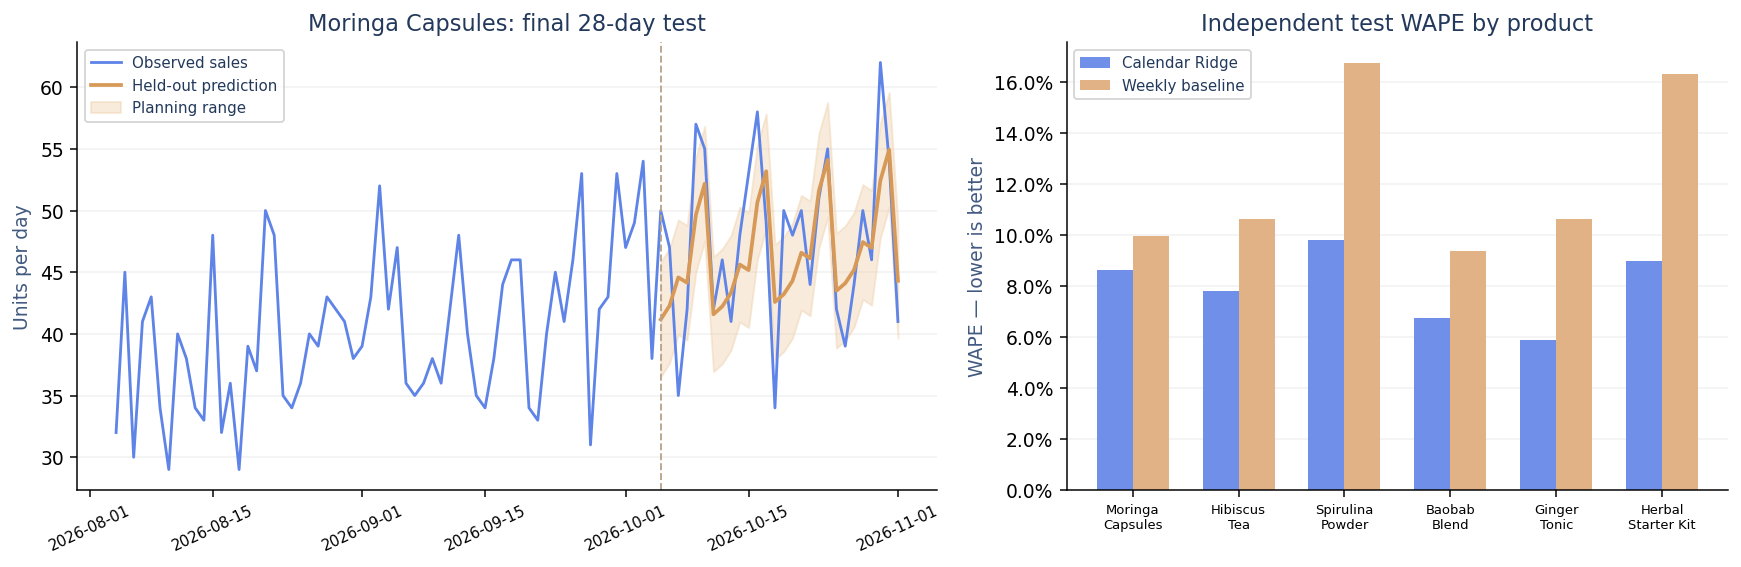

In [4]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
with (ROOT/'dist/data/demo_sales.csv').open() as f:
    rows=list(csv.DictReader(f))
selected=report['products'][0]
records=[r for r in rows if r['product']==selected['product']]
dates=[date.fromisoformat(r['date']) for r in records]
days=np.array([(d-date(1970,1,1)).days for d in dates])
units=np.array([float(r['units']) for r in records])
cut=len(units)-28
fitted=ridge_fit(days[:cut],units[:cut],int(days[0]),True)
pred=ridge_predict(fitted,days[cut:],int(days[0]),True) if selected['selected']=='ridge' else weekly(units[:cut],28)
plt.rcParams.update({'font.size':10,'axes.spines.top':False,'axes.spines.right':False,'axes.labelcolor':'#425a80','text.color':'#23395c'})
fig,axes=plt.subplots(1,2,figsize=(13,4.3),gridspec_kw={'width_ratios':[1.3,1]})
axes[0].plot(dates[-90:],units[-90:],color='#5f84e7',lw=1.5,label='Observed sales')
axes[0].plot(dates[cut:],pred,color='#d79958',lw=2,label='Held-out prediction')
axes[0].fill_between(dates[cut:],np.maximum(0,pred-selected['range_radius']),pred+selected['range_radius'],color='#edcba2',alpha=.38,label='Planning range')
axes[0].axvline(dates[cut],ls='--',color='#b8a58b',lw=1)
axes[0].set(title='Moringa Capsules: final 28-day test',ylabel='Units per day')
axes[0].tick_params(axis='x',labelrotation=25,labelsize=8)
axes[0].legend(fontsize=8,loc='upper left')
x=np.arange(len(report['products']))
axes[1].bar(x-.17,[p['ridge_test']['wape'] for p in report['products']],.34,color='#6f8fe8',label='Calendar Ridge')
axes[1].bar(x+.17,[p['weekly_test']['wape'] for p in report['products']],.34,color='#e0b285',label='Weekly baseline')
axes[1].set_xticks(x,[p['product'].replace(' ','\n',1) for p in report['products']],fontsize=7)
axes[1].yaxis.set_major_formatter(PercentFormatter(1))
axes[1].set(title='Independent test WAPE by product',ylabel='WAPE — lower is better')
axes[1].legend(fontsize=8)
for ax in axes:ax.grid(axis='y',alpha=.18);ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(ROOT/'project/model_evaluation.png',dpi=180,bbox_inches='tight')
plt.show()

## 5. Forecast the portfolio

The shaded bounds are sums of the product planning ranges. They do not constitute an 80% portfolio confidence interval. No future actuals are used.

Forecast units, next 30 days: 6886.706
All records shown here are synthetic.


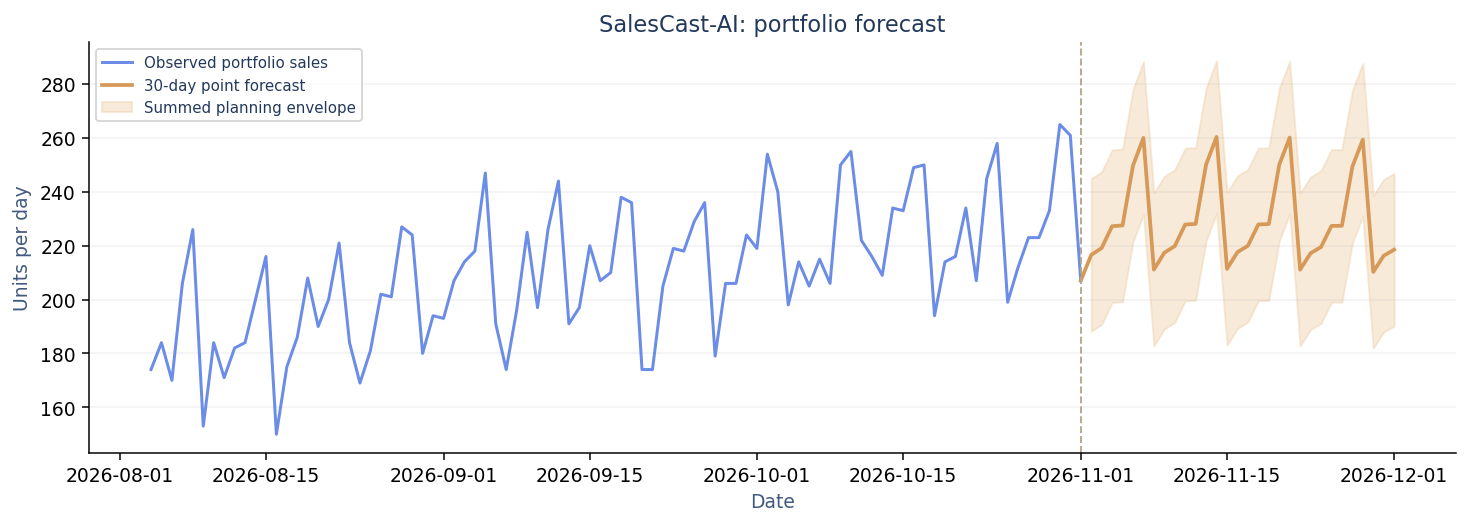

In [5]:
fixtures=json.loads((ROOT/'project/python_fixtures.json').read_text())
historical=np.sum([np.array([float(r['units']) for r in rows if r['product']==p['product']]) for p in CATALOG],axis=0)
forecast=np.sum([np.array(p['forecast_first_30']) for p in fixtures],axis=0)
lower=np.sum([np.maximum(0,np.array(p['forecast_first_30'])-p['radius']) for p in fixtures],axis=0)
upper=np.sum([np.array(p['forecast_first_30'])+p['radius'] for p in fixtures],axis=0)
future_dates=[dates[-1]+timedelta(days=i+1) for i in range(30)]
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(dates[-90:],historical[-90:],color='#6b8de7',lw=1.6,label='Observed portfolio sales')
ax.plot([dates[-1],*future_dates],[historical[-1],*forecast],color='#d79958',lw=2,label='30-day point forecast')
ax.fill_between(future_dates,lower,upper,color='#edcba2',alpha=.4,label='Summed planning envelope')
ax.axvline(dates[-1],color='#b8a58b',ls='--',lw=1)
ax.set(title='SalesCast-AI: portfolio forecast',ylabel='Units per day',xlabel='Date')
ax.grid(axis='y',alpha=.18);ax.legend(fontsize=8);fig.tight_layout()
fig.savefig(ROOT/'project/portfolio_forecast.png',dpi=180,bbox_inches='tight')
print('Forecast units, next 30 days:',round(float(forecast.sum()),3))
print('All records shown here are synthetic.')
plt.show()

## 6. Reproduce the browser result

`project/python_fixtures.json` contains the learned coefficients, selected model, planning-range radius, first 30 forecasts, and test predictions for each product. `npm test` compares these against the independent browser implementation and verifies chronology, CSV validation, and stock calculations.

Run the app with `python -m http.server 8000 --directory dist`, then open http://localhost:8000. To forecast your own sales without editing this demonstration pipeline, use the app’s validated CSV import.

Reference: [scikit-learn Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html).